In [71]:
#Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import auc
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [88]:
data = 'https://raw.githubusercontent.com/Javier-Gutierrez/machine-learning-zoomcamp/refs/heads/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
df = pd.read_csv(data)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
#checking the general informacion of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [5]:
df.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [6]:
#Checking for columns with missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [89]:
#Categorical

categorical = ['lead_source', 'industry', 'employment_status', 'location','converted']

In [90]:
#Numerical

numerical =  ['annual_income', 'number_of_courses_viewed', 'interaction_count','lead_score']

In [91]:
#Filling categorical missing values

for col in categorical:
    df[col] = df[col].fillna('NA')

print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [92]:
#Filling numerical missing values

for col in numerical:
    df[col] = df[col].fillna(0)

print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [93]:
#Splitting the dataset
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [94]:
#Reseting index

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

In [95]:
#Spliting the target

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [96]:
y_full_train = df_full_train.converted.values



In [ ]:
#Deleting the target from my datasets for avoiding problems

del df_train['converted']
del df_val['converted']
del df_test['converted']
del df_full_train['converted']


In [36]:

#Making One-hot encoding of train dataset

#Train dataset
train_dicts = df_train.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train = DictVectorizer(sparse=False)
X_train = dv_train.fit_transform(train_dicts)

#Validation dataset
val_dicts = df_val.to_dict(orient='records')
dv_val = DictVectorizer(sparse=False)
X_val = dv_val.fit_transform(val_dicts)

In [ ]:
#Logistic regression

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The 

In [18]:
#Soft prediction

y_pred = model.predict_proba(X_val)[:,1]
y_pred

array([0.61725691, 0.44364108, 0.60433996, 0.64562246, 0.52214159,
       0.77885722, 0.60698076, 0.54481903, 0.76770971, 0.52765495,
       0.75038798, 0.6470054 , 0.56857815, 0.51044645, 0.59921425,
       0.46620745, 0.62786484, 0.69167143, 0.69082953, 0.59101344,
       0.49964695, 0.55590822, 0.65303933, 0.6079306 , 0.7231576 ,
       0.51616805, 0.56141276, 0.57206269, 0.67043904, 0.55599224,
       0.63613322, 0.70337215, 0.45463513, 0.61897288, 0.65250689,
       0.42775649, 0.63943096, 0.62315373, 0.6602988 , 0.51736304,
       0.53774147, 0.76074014, 0.48326071, 0.74151288, 0.63662375,
       0.41194601, 0.45371292, 0.6417333 , 0.43851314, 0.87060984,
       0.72468973, 0.75643941, 0.5296636 , 0.66736678, 0.50444495,
       0.57644782, 0.72318139, 0.72497254, 0.6507741 , 0.628958  ,
       0.7217776 , 0.59231588, 0.70824617, 0.61451576, 0.49691434,
       0.74445314, 0.52773381, 0.61402574, 0.55979831, 0.59024431,
       0.69368703, 0.72962242, 0.76111566, 0.60744404, 0.52501

In [27]:
y_pred.shape

(1000,)

In [19]:
#Confusion values
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
t = 0.5
predict_positive = (y_pred >=t)
predict_negative = (y_pred <t)


In [20]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [21]:
#Confusion matrix

confusion_matrix = np.array([
    [tn,fp],
    [fn,tp]
])

confusion_matrix

array([[ 87, 316],
       [ 39, 558]])

In [22]:
#Relative numbers

confusion_matrix/confusion_matrix.sum()

array([[0.087, 0.316],
       [0.039, 0.558]])

In [23]:
#TPR & FPR
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)
fpr

np.float64(0.7841191066997518)

In [24]:

scores = []

thresholds = np.linspace(0,1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >=t)
    predict_negative = (y_pred <t)
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [25]:
colmumns = ['thresholds','tp', 'fp', 'fn', 'tn']

df_scores=pd.DataFrame(scores, columns=colmumns)

In [26]:
#Checking TPR & FPR in each threshold

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

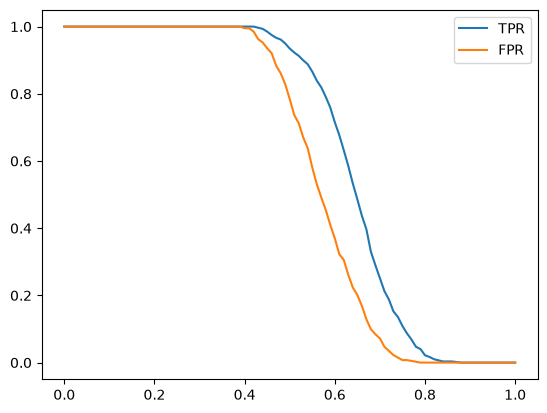

In [27]:
plt.plot(df_scores.thresholds, df_scores['tpr'], label = 'TPR')
plt.plot(df_scores.thresholds, df_scores['fpr'], label = 'FPR')
plt.legend()

In [28]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0,1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        predict_positive = (y_pred >=t)
        predict_negative = (y_pred <t)
        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))
    colmumns = ['thresholds','tp', 'fp', 'fn', 'tn']

    df_scores=pd.DataFrame(scores, columns=colmumns)
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [29]:
#Num for ideal model

num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
y_ideal = np.repeat([0,1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0,1, len(y_val))
((y_ideal_pred >= 0.403) == y_ideal).mean()

np.float64(1.0)

In [30]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

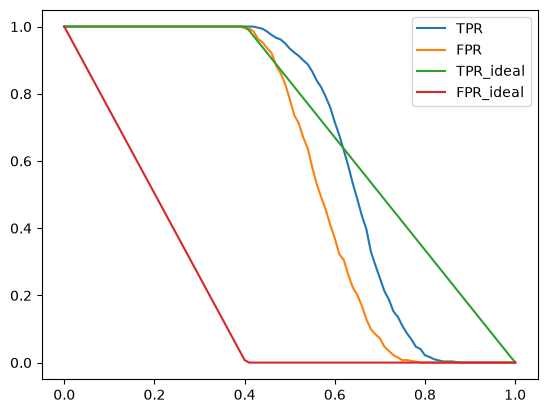

In [31]:
plt.plot(df_scores.thresholds, df_scores['tpr'], label = 'TPR')
plt.plot(df_scores.thresholds, df_scores['fpr'], label = 'FPR')
plt.plot(df_ideal.thresholds, df_ideal['tpr'], label = 'TPR_ideal')
plt.plot(df_ideal.thresholds, df_ideal['fpr'], label = 'FPR_ideal')
plt.legend()

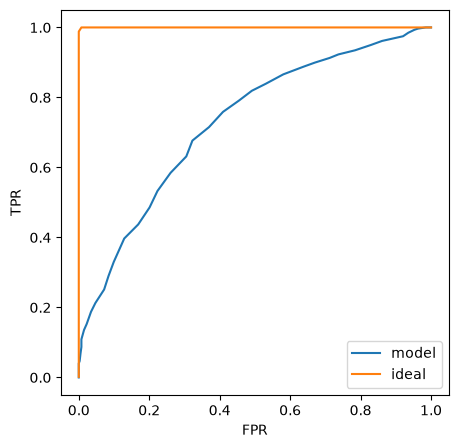

In [32]:
plt.figure(figsize=(5,5))
plt.plot(df_scores.fpr, df_scores.tpr, label='model')
plt.plot(df_ideal.fpr, df_ideal.tpr, label='ideal')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

In [33]:
#AUC

auc(df_scores.fpr, df_scores.tpr)


0.7286286685703123

In [34]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.7287097189836693

In [ ]:
#Q1 ROC AUC SCORE 
for var in numerical:

    auc = roc_auc_score (y_train, df_train[var])

    if auc < 0.5:
        auc = roc_auc_score (y_train, -df_train[var])
        print('negative correlation')

    print(f'var: {var} -> AUC: {auc:.4f}')

var: annual_income -> AUC: 0.6024
var: number_of_courses_viewed -> AUC: 0.7199
var: interaction_count -> AUC: 0.7667
var: lead_score -> AUC: 0.7879


In [51]:
#Q2 
#Making One-hot encoding of train dataset

#Train dataset
train_dicts = df_train.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train = DictVectorizer(sparse=False)
X_train = dv_train.fit_transform(train_dicts)

#Validation dataset
val_dicts = df_val.to_dict(orient='records')
dv_val = DictVectorizer(sparse=False)
X_val = dv_val.fit_transform(val_dicts)

#Logistic regression

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

#Soft prediction

y_pred = model.predict_proba(X_val)[:,1]

round(roc_auc_score(y_val, y_pred),3)



0.729

In [ ]:
def prec_recall_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0,1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        predict_positive = (y_pred >=t)
        predict_negative = (y_pred <t)
        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))
    colmumns = ['thresholds','tp', 'fp', 'fn', 'tn']

    df_scores=pd.DataFrame(scores, columns=colmumns)
    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['F1_score'] = 2 * ((df_scores.precision*df_scores.recall) / (df_scores.precision + df_scores.recall))

    return df_scores

In [53]:
df_prec_recall = prec_recall_dataframe(y_val, y_pred)
df_prec_recall[::10]

,thresholds,tp,fp,fn,tn,precision,recall,F1_score
0,0.0,597,403,0,0,0.597000,1.000000,0.747652
10,0.1,597,403,0,0,0.597000,1.000000,0.747652
20,0.2,597,403,0,0,0.597000,1.000000,0.747652
30,0.3,597,403,0,0,0.597000,1.000000,0.747652
40,0.4,597,401,0,2,0.598196,1.000000,0.748589
50,0.5,558,316,39,87,0.638444,0.934673,0.758668
60,0.6,427,149,170,254,0.741319,0.715243,0.728048
70,0.7,150,29,447,374,0.837989,0.251256,0.386598
80,0.8,13,0,584,403,1.000000,0.021776,0.042623
90,0.9,0,0,597,403,NaN,0.000000,NaN


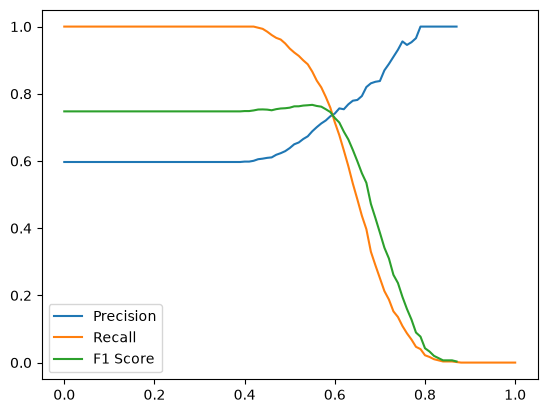

In [55]:
plt.plot(df_prec_recall.thresholds, df_prec_recall.precision, label = 'Precision')
plt.plot(df_prec_recall.thresholds, df_prec_recall.recall, label = 'Recall')
plt.plot(df_prec_recall.thresholds, df_prec_recall.F1_score, label = 'F1 Score')
plt.legend()

In [62]:
df_prec_recall.loc[df_prec_recall.F1_score.idxmax()]

thresholds      0.550000
tp            517.000000
fp            234.000000
fn             80.000000
tn            169.000000
precision       0.688415
recall          0.865997
F1_score        0.767062
Name: 55, dtype: float64

In [141]:
#Cross Validation

def train (df_train, y_train, C=1):

    dicts = df_train[categorical + numerical].drop(columns=['converted']).to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [142]:
def predict (df_train, dv, model):
    dicts = df_train[categorical + numerical].drop(columns=['converted']).to_dict(orient='records')

    X= dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred


In [108]:
from sklearn.model_selection import KFold

In [143]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1 )

In [144]:


for C in [0.000001, 0.001, 1]:

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_kfold = df_full_train.iloc[train_idx]
        df_val_kfold = df_full_train.iloc[val_idx]

        df_train_kfold.drop(columns=['converted'])
        df_val_kfold.drop(columns=['converted'])

        y_train_kfold = df_train_kfold.converted.values
        y_val_kfold = df_val_kfold.converted.values

        dv, model = train(df_train_kfold, y_train_kfold, C=C)
        y_pred_kfold = predict(df_val_kfold, dv, model)

        auc = roc_auc_score(y_val_kfold, y_pred_kfold)
        
        scores.append(auc)

    print(f'C={C} Mean={np.mean(scores) } ')

C=1e-06 Mean=0.6156839145998391 
C=0.001 Mean=0.7444264055019039 
C=1 Mean=0.731096227714055 


In [131]:
np.std(scores)

np.float64(0.013567633170191868)

In [145]:
scores

[0.7415320910973084,
 0.7382740460482536,
 0.7136156870807742,
 0.7413876758854925,
 0.7206716384584467]